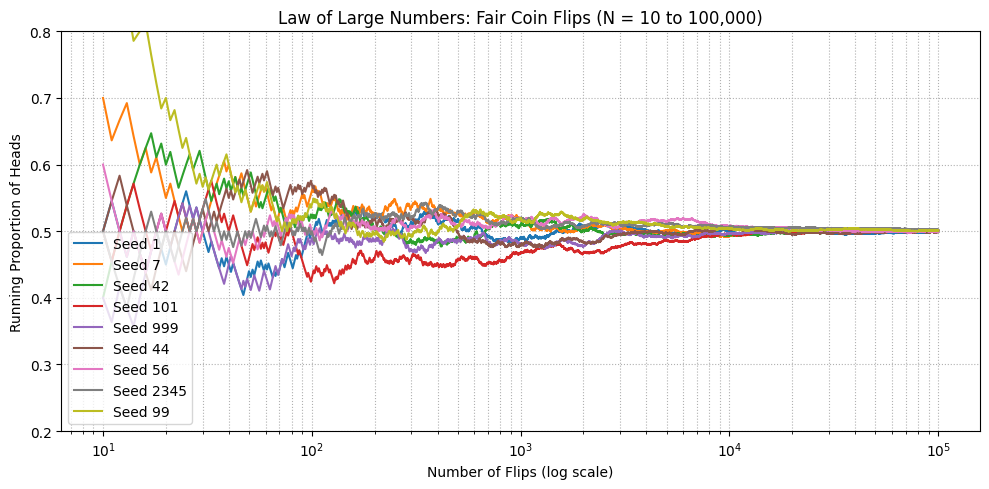

Theoretical E[X] per trade: 0.0200

--- 100 Trades per Trader (1,000 Traders) ---
Theoretical Expected PnL : 2.00
Simulated Mean PnL       : 1.66
Traders in the red (< 0) : 39.2%

--- 10,000 Trades per Trader (1,000 Traders) ---
Theoretical Expected PnL : 200.00
Simulated Mean PnL       : 207.13
Traders in the red (< 0) : 0.8%



In [25]:
import numpy as np
import matplotlib.pyplot as plt

N = 100_000
seeds = [1, 7, 42, 101, 999,44,56,2345,99]
n_trials = np.arange(1, N + 1)

plt.figure(figsize=(10, 5))

for s in seeds:
    rng = np.random.default_rng(seed=s)
    flips = rng.integers(0, 2, size=N)  # 0 = Tails, 1 = Heads
    running_mean = np.cumsum(flips) / n_trials
    plt.plot(n_trials[9:], running_mean[9:], alpha=1, label=f"Seed {s}")


plt.xscale('log')
plt.ylim(0.2, 0.8)
plt.title('Law of Large Numbers: Fair Coin Flips (N = 10 to 100,000)')
plt.xlabel('Number of Flips (log scale)')
plt.ylabel('Running Proportion of Heads')
plt.grid(True, which='both', linestyle=':', alpha=1)
plt.legend()
plt.tight_layout()
plt.show()

# Analytical Expected Value per trade: (0.51 * 1) + (0.49 * -1) = +0.02
ev_per_trade = 0.51 * 1 + 0.49 * (-1)
print(f"Theoretical E[X] per trade: {ev_per_trade:.4f}\n")

rng = np.random.default_rng(seed=42)
n_traders = 1_000

for n_trades in [100, 10_000]:
    # Shape: (1000 traders, n_trades)
    trades = rng.choice([1, -1], size=(n_traders, n_trades), p=[0.51, 0.49])
    final_pnl = trades.sum(axis=1)

    mean_pnl = final_pnl.mean()
    theoretical_pnl = n_trades * ev_per_trade
    pct_losing = np.mean(final_pnl < 0) * 100

    print(f"--- {n_trades:,} Trades per Trader ({n_traders:,} Traders) ---")
    print(f"Theoretical Expected PnL : {theoretical_pnl:.2f}")
    print(f"Simulated Mean PnL       : {mean_pnl:.2f}")
    print(f"Traders in the red (< 0) : {pct_losing:.1f}%\n")
